In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Device: cuda
GPU: Tesla T4
Total samples: 290
   Image   Mask
0  0.jpg  0.png
1  1.jpg  1.png
2  2.jpg  2.png
3  3.jpg  3.png
4  4.jpg  4.png

Dataset split
Total: 290
Train: 232
Validation: 58

Train batches: 15
Validation batches: 4

Positive pixel ratio
Train: 0.3836194400129647
Validation: 0.4129199323983028

Trainable parameters: 31,043,521
Epoch 01/40 | Train Loss: 0.5091 | Val Loss: 0.5693 | IoU: 0.5685 | Dice: 0.7063 | LR: 1.00e-04
  -> Best model saved
Epoch 02/40 | Train Loss: 0.3956 | Val Loss: 0.4610 | IoU: 0.5791 | Dice: 0.7175 | LR: 1.00e-04
  -> Best model saved
Epoch 03/40 | Train Loss: 0.3688 | Val Loss: 0.3464 | IoU: 0.6907 | Dice: 0.8048 | LR: 1.00e-04
  -> Best model saved
Epoch 04/40 | Train Loss: 0.3613 | Val Loss: 0.3230 | IoU: 0.7113 | Dice: 0.8213 | LR: 1.00e-04
  -> Best model saved
Epoch 05/40 | Train Loss: 0.3525 | Val Loss: 0.3237 | IoU: 0.7030 | Dice: 0.8139 | LR: 1.00e-04
Epoch 06/40 | Train Loss: 0.3474 | Val Loss: 0.3069 | IoU: 0.6998 | Dice: 0.8112 | L

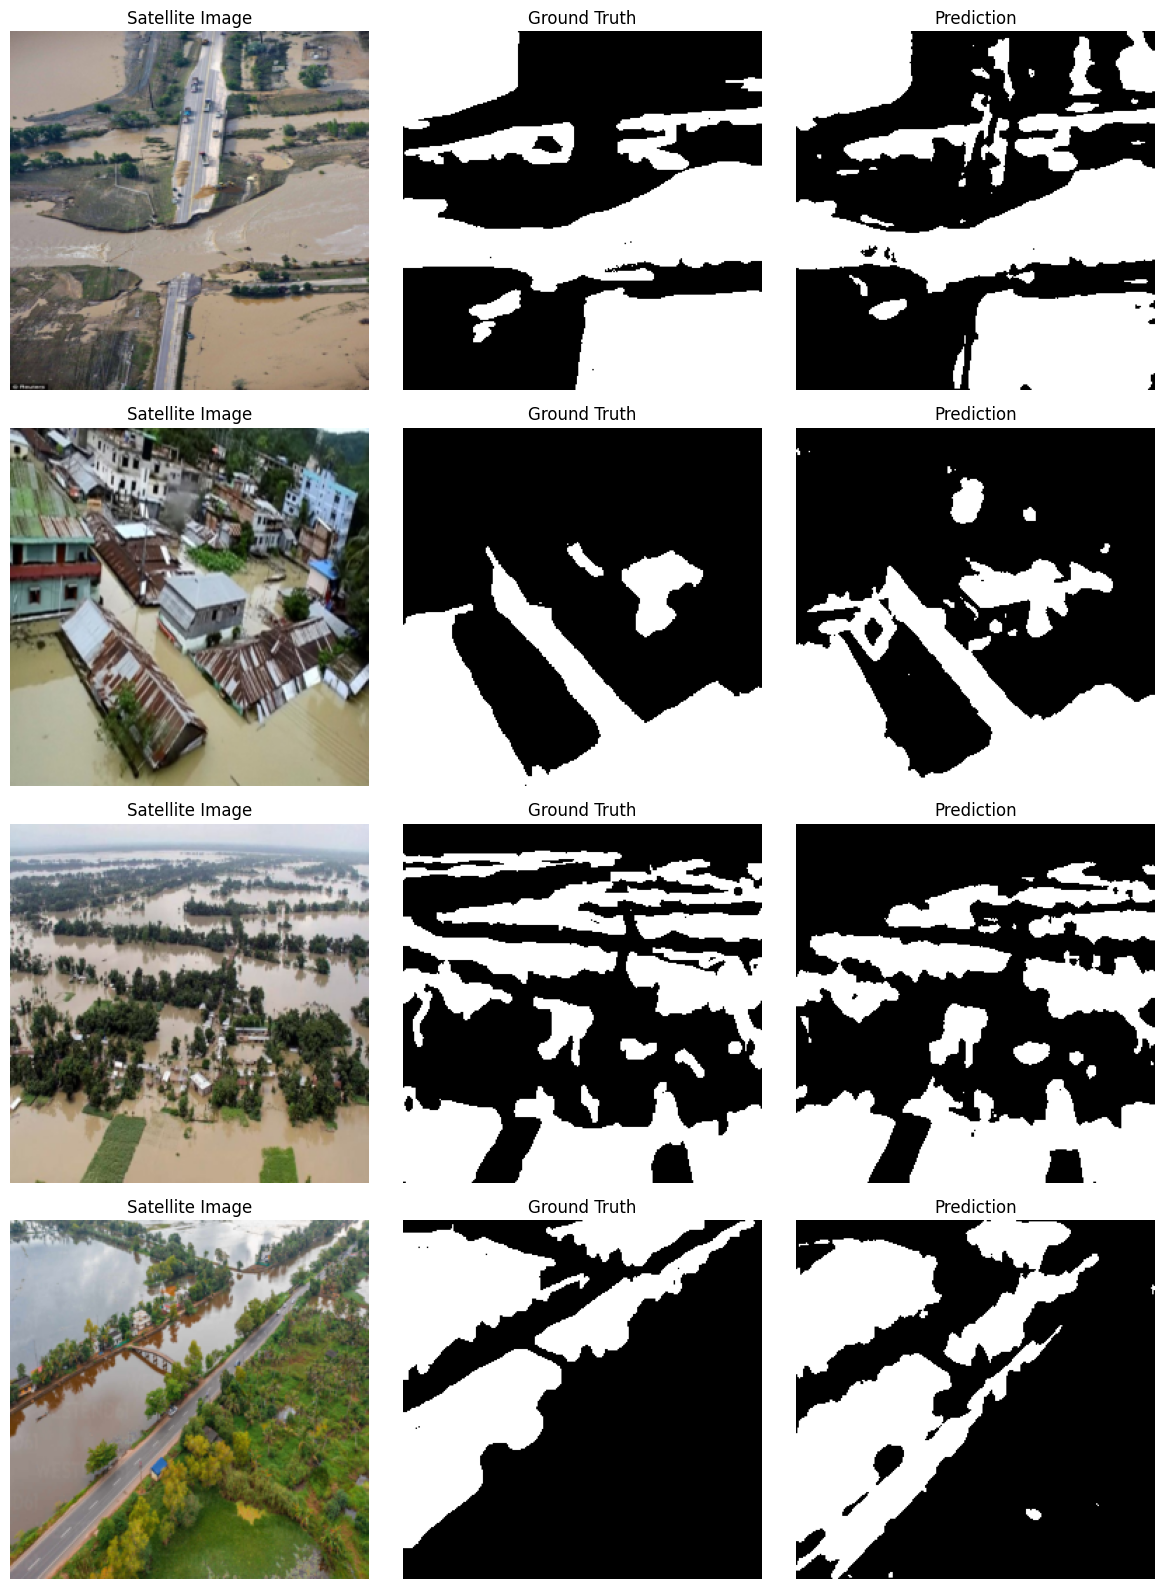

DONE !!!!!


In [5]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF

from sklearn.model_selection import train_test_split

# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. PATHS
# ============================================================

img_path = "/kaggle/input/datasets/geethchandchinni/cosmo-segmentation/Segmentation dataset -20241018T225923Z-001/Segmentation dataset/Segmentation dataset/Image"
mask_path = "/kaggle/input/datasets/geethchandchinni/cosmo-segmentation/Segmentation dataset -20241018T225923Z-001/Segmentation dataset/Segmentation dataset/Mask"
csv_path = "/kaggle/input/datasets/geethchandchinni/cosmo-segmentation/Segmentation dataset -20241018T225923Z-001/Segmentation dataset/Segmentation dataset/metadata.csv"

df = pd.read_csv(csv_path)

print("Total samples:", len(df))
print(df.head())


# ============================================================
# 3. DATASET
# ============================================================

class FloodDataset(Dataset):

    def __init__(
        self,
        dataframe,
        img_dir,
        mask_dir,
        augment=False
    ):
        self.data = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.augment = augment

        self.image_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.BILINEAR
            ),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_resize = transforms.Resize(
            (256, 256),
            interpolation=transforms.InterpolationMode.NEAREST
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        img_name = os.path.join(
            self.img_dir,
            self.data.iloc[idx, 0]
        )

        mask_name = os.path.join(
            self.mask_dir,
            self.data.iloc[idx, 1]
        )

        image = Image.open(img_name).convert("RGB")
        mask = Image.open(mask_name).convert("L")

        # ----------------------------------------------------
        # AUGMENTATION
        # Applied BEFORE normalization/resizing
        # and ONLY for training dataset
        # ----------------------------------------------------

        if self.augment:

            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            if random.random() < 0.5:
                image = TF.vflip(image)
                mask = TF.vflip(mask)

            if random.random() < 0.5:
                angle = random.uniform(-30, 30)

                image = TF.rotate(
                    image,
                    angle,
                    interpolation=transforms.InterpolationMode.BILINEAR
                )

                mask = TF.rotate(
                    mask,
                    angle,
                    interpolation=transforms.InterpolationMode.NEAREST
                )

        image = self.image_transform(image)

        mask = self.mask_resize(mask)
        mask = TF.to_tensor(mask)

        mask = (mask > 0.5).float()

        return image, mask


# ============================================================
# 4. TRAIN / VALIDATION SPLIT
# ============================================================

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

print("\nDataset split")
print("Total:", len(df))
print("Train:", len(train_df))
print("Validation:", len(val_df))


# ============================================================
# 5. DATASETS
# ============================================================

train_dataset = FloodDataset(
    train_df,
    img_path,
    mask_path,
    augment=True
)

val_dataset = FloodDataset(
    val_df,
    img_path,
    mask_path,
    augment=False
)


# ============================================================
# 6. DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ============================================================
# 7. CHECK MASK DISTRIBUTION
# ============================================================

def calculate_positive_ratio(dataset):

    total_pixels = 0
    positive_pixels = 0

    for i in range(len(dataset)):

        _, mask = dataset[i]

        positive_pixels += mask.sum().item()
        total_pixels += mask.numel()

    return positive_pixels / total_pixels


train_positive_ratio = calculate_positive_ratio(train_dataset)
val_positive_ratio = calculate_positive_ratio(val_dataset)

print("\nPositive pixel ratio")
print("Train:", train_positive_ratio)
print("Validation:", val_positive_ratio)


# ============================================================
# 8. U-NET
# ============================================================

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.0
    ):

        super().__init__()

        layers = [
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        ]

        if dropout > 0:
            layers.append(
                nn.Dropout2d(dropout)
            )

        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):

        super().__init__()

        features = [64, 128, 256, 512]

        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Encoder
        for i, feature in enumerate(features):

            dropout = 0.10 if i < 2 else 0.20

            self.downs.append(
                DoubleConv(
                    in_channels,
                    feature,
                    dropout=dropout
                )
            )

            in_channels = feature

        # Bottleneck
        self.bottleneck = DoubleConv(
            features[-1],
            features[-1] * 2,
            dropout=0.30
        )

        # Decoder
        for feature in reversed(features):

            self.ups.append(
                nn.ConvTranspose2d(
                    feature * 2,
                    feature,
                    kernel_size=2,
                    stride=2
                )
            )

            self.ups.append(
                DoubleConv(
                    feature * 2,
                    feature,
                    dropout=0.10
                )
            )

        self.final_conv = nn.Conv2d(
            features[0],
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        skip_connections = []

        for down in self.downs:

            x = down(x)

            skip_connections.append(x)

            x = self.pool(x)

        x = self.bottleneck(x)

        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):

            x = self.ups[idx](x)

            skip_connection = skip_connections[idx // 2]

            if x.shape[2:] != skip_connection.shape[2:]:
                x = F.interpolate(
                    x,
                    size=skip_connection.shape[2:],
                    mode="bilinear",
                    align_corners=False
                )

            x = torch.cat(
                [skip_connection, x],
                dim=1
            )

            x = self.ups[idx + 1](x)

        return self.final_conv(x)


# ============================================================
# 9. MODEL
# ============================================================

model = UNet(
    in_channels=3,
    out_channels=1
).to(device)


def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


num_params = count_parameters(model)

print("\nTrainable parameters:", f"{num_params:,}")


# ============================================================
# 10. LOSS FUNCTIONS
# ============================================================

bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1e-6):

    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        probabilities * targets
    ).sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1 - dice.mean()


def combined_loss(logits, targets):

    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice


# ============================================================
# 11. METRICS
# ============================================================

def calculate_metrics(logits, targets, threshold=0.5):

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        predictions * targets
    ).sum(dim=1)

    pred_area = predictions.sum(dim=1)
    target_area = targets.sum(dim=1)

    union = (
        pred_area
        + target_area
        - intersection
    )

    dice = (
        2 * intersection + 1e-6
    ) / (
        pred_area
        + target_area
        + 1e-6
    )

    iou = (
        intersection + 1e-6
    ) / (
        union + 1e-6
    )

    return iou.mean().item(), dice.mean().item()


# ============================================================
# 12. OPTIMIZER + SCHEDULER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=4
)


# ============================================================
# 13. TRAINING / VALIDATION
# ============================================================

def train_one_epoch():

    model.train()

    total_loss = 0

    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = combined_loss(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)


def validate():

    model.eval()

    total_loss = 0
    total_iou = 0
    total_dice = 0
    batches = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            logits = model(images)

            loss = combined_loss(
                logits,
                masks
            )

            iou, dice = calculate_metrics(
                logits,
                masks
            )

            total_loss += loss.item()
            total_iou += iou
            total_dice += dice

            batches += 1

    return (
        total_loss / batches,
        total_iou / batches,
        total_dice / batches
    )


# ============================================================
# 14. FINAL TRAINING
# ============================================================

NUM_EPOCHS = 40
PATIENCE = 8

best_val_loss = float("inf")
best_val_iou = 0
best_val_dice = 0
best_epoch = 0
epochs_without_improvement = 0

history = []

best_model_path = "/kaggle/working/best_flood_unet.pth"


for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch()

    val_loss, val_iou, val_dice = validate()

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_iou": val_iou,
        "val_dice": val_dice,
        "lr": current_lr
    })

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"IoU: {val_iou:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_iou = val_iou
        best_val_dice = val_dice
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_iou": val_iou,
                "val_dice": val_dice
            },
            best_model_path
        )

        print("  -> Best model saved")

    else:

        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print("Early stopping")

            break


# ============================================================
# 15. TRAINING SUMMARY
# ============================================================

history_df = pd.DataFrame(history)

print("\n==============================")
print("FINAL EXPERIMENT")
print("==============================")

print("Total samples:", len(df))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("Input size: 256 x 256")
print("Batch size:", BATCH_SIZE)
print("Optimizer: Adam")
print("Initial learning rate: 1e-4")
print("Loss: 0.5 * BCE + 0.5 * Dice")
print("Augmentation: HFlip + VFlip + Rotation")
print("Dropout: 0.10 / 0.20 / 0.30")
print("Trainable parameters:", f"{num_params:,}")

print("\nBest epoch:", best_epoch)
print("Best validation loss:", f"{best_val_loss:.4f}")
print("Best validation IoU:", f"{best_val_iou:.4f}")
print("Best validation Dice:", f"{best_val_dice:.4f}")

print("\nBest model saved to:")
print(best_model_path)


# ============================================================
# 16. LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("\nLoaded best checkpoint from epoch:", checkpoint["epoch"])


# ============================================================
# 17. FINAL VALIDATION PASS
# ============================================================

final_val_loss, final_iou, final_dice = validate()

print("\n==============================")
print("FINAL VALIDATION")
print("==============================")

print("Validation Loss:", f"{final_val_loss:.4f}")
print("Validation IoU :", f"{final_iou:.4f}")
print("Validation Dice:", f"{final_dice:.4f}")


# ============================================================
# 18. SAVE TRAINING HISTORY
# ============================================================

history_df.to_csv(
    "/kaggle/working/training_history.csv",
    index=False
)

print("\nTraining history saved.")


# ============================================================
# 19. VISUALIZE PREDICTIONS
# ============================================================

import matplotlib.pyplot as plt


def show_predictions(
    model,
    dataset,
    num_samples=4
):

    model.eval()

    indices = np.random.choice(
        len(dataset),
        size=min(num_samples, len(dataset)),
        replace=False
    )

    fig, axes = plt.subplots(
        len(indices),
        3,
        figsize=(12, 4 * len(indices))
    )

    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    with torch.no_grad():

        for row, idx in enumerate(indices):

            image, true_mask = dataset[idx]

            logits = model(
                image.unsqueeze(0).to(device)
            )

            prediction = (
                torch.sigmoid(logits)
                >= 0.5
            ).float()

            image_display = (
                image.cpu() * std + mean
            )

            image_display = (
                image_display
                .permute(1, 2, 0)
                .clamp(0, 1)
            )

            axes[row, 0].imshow(
                image_display
            )

            axes[row, 0].set_title(
                "Satellite Image"
            )

            axes[row, 1].imshow(
                true_mask.squeeze(),
                cmap="gray"
            )

            axes[row, 1].set_title(
                "Ground Truth"
            )

            axes[row, 2].imshow(
                prediction.squeeze().cpu(),
                cmap="gray"
            )

            axes[row, 2].set_title(
                "Prediction"
            )

            for col in range(3):
                axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(
    model,
    val_dataset,
    num_samples=4
)


print("DONE !!!!!")

In [6]:
# ============================================================
# PER-IMAGE VALIDATION METRICS
# ============================================================

def evaluate_per_image(model, dataset, threshold=0.5):

    model.eval()

    results = []

    with torch.no_grad():

        for idx in range(len(dataset)):

            image, mask = dataset[idx]

            image_input = image.unsqueeze(0).to(device)

            logits = model(image_input)

            probabilities = torch.sigmoid(logits)

            prediction = (
                probabilities >= threshold
            ).float()

            pred = prediction.squeeze().flatten()
            target = mask.squeeze().to(device).flatten()

            intersection = (pred * target).sum()

            pred_area = pred.sum()
            target_area = target.sum()

            union = (
                pred_area
                + target_area
                - intersection
            )

            iou = (
                intersection + 1e-6
            ) / (
                union + 1e-6
            )

            dice = (
                2 * intersection + 1e-6
            ) / (
                pred_area
                + target_area
                + 1e-6
            )

            results.append({
                "index": idx,
                "image": val_df.iloc[idx, 0],
                "mask": val_df.iloc[idx, 1],
                "iou": iou.item(),
                "dice": dice.item(),
                "target_pixels": target.sum().item(),
                "predicted_pixels": pred.sum().item()
            })

    return pd.DataFrame(results)


per_image_results = evaluate_per_image(
    model,
    val_dataset,
    threshold=0.5
)

print(per_image_results)

    index     image      mask       iou      dice  target_pixels  \
0       0  2035.jpg  2035.png  0.821793  0.902181        30602.0   
1       1  1056.jpg  1056.png  0.432738  0.604071        15527.0   
2       2    45.jpg    45.png  0.946159  0.972335        29095.0   
3       3  3072.jpg  3072.png  0.786903  0.880745        17178.0   
4       4  3040.jpg  3040.png  0.842821  0.914708        51316.0   
5       5  3022.jpg  3022.png  0.771354  0.870920        20201.0   
6       6  1022.jpg  1022.png  0.497653  0.664577         8967.0   
7       7  3015.jpg  3015.png  0.919032  0.957808        56409.0   
8       8     9.jpg     9.png  0.794244  0.885324        24390.0   
9       9  2041.jpg  2041.png  0.565475  0.722432        57434.0   
10     10  3044.jpg  3044.png  0.856186  0.922522        32983.0   
11     11  1071.jpg  1071.png  0.698390  0.822414        29326.0   
12     12    33.jpg    33.png  0.747064  0.855222        36373.0   
13     13  1076.jpg  1076.png  0.675656  0.80643

In [7]:
print("\nPer-image statistics")

print(
    per_image_results[
        ["iou", "dice"]
    ].describe()
)


Per-image statistics
             iou       dice
count  58.000000  58.000000
mean    0.752765   0.851006
std     0.136259   0.104982
min     0.224244   0.366339
25%     0.711597   0.831498
50%     0.781788   0.877523
75%     0.845003   0.915990
max     0.946159   0.972335


In [8]:
worst_images = per_image_results.sort_values(
    "iou"
).head(10)

print(worst_images)

    index     image      mask       iou      dice  target_pixels  \
23     23  2052.jpg  2052.png  0.224244  0.366339        30255.0   
24     24  2026.jpg  2026.png  0.415434  0.587006        12020.0   
1       1  1056.jpg  1056.png  0.432738  0.604071        15527.0   
6       6  1022.jpg  1022.png  0.497653  0.664577         8967.0   
31     31  2007.jpg  2007.png  0.518321  0.682756        18128.0   
9       9  2041.jpg  2041.png  0.565475  0.722432        57434.0   
37     37  3010.jpg  3010.png  0.574267  0.729568        34163.0   
21     21  1086.jpg  1086.png  0.603299  0.752572        24316.0   
57     57  3065.jpg  3065.png  0.639127  0.779839        16094.0   
54     54  1009.jpg  1009.png  0.671444  0.803430        31959.0   

    predicted_pixels  
23           15566.0  
24           23489.0  
1            10215.0  
6             9219.0  
31           22894.0  
9            35347.0  
37           20346.0  
21           32747.0  
57           11781.0  
54           45591.0 

In [9]:
best_images = per_image_results.sort_values(
    "iou",
    ascending=False
).head(10)

print(best_images)

    index     image      mask       iou      dice  target_pixels  \
2       2    45.jpg    45.png  0.946159  0.972335        29095.0   
7       7  3015.jpg  3015.png  0.919032  0.957808        56409.0   
14     14  1016.jpg  1016.png  0.910967  0.953409        27595.0   
49     49  3016.jpg  3016.png  0.897382  0.945916        32154.0   
30     30    42.jpg    42.png  0.891302  0.942527        30094.0   
38     38  3056.jpg  3056.png  0.884731  0.938841        33001.0   
28     28  2011.jpg  2011.png  0.875854  0.933819        33307.0   
33     33  3014.jpg  3014.png  0.863188  0.926571        35838.0   
40     40  3043.jpg  3043.png  0.862352  0.926089        29603.0   
56     56  3079.jpg  3079.png  0.859533  0.924461        36154.0   

    predicted_pixels  
2            30619.0  
7            55555.0  
14           29176.0  
49           33281.0  
30           32005.0  
38           33579.0  
28           32316.0  
33           34393.0  
40           30618.0  
56           34075.0 

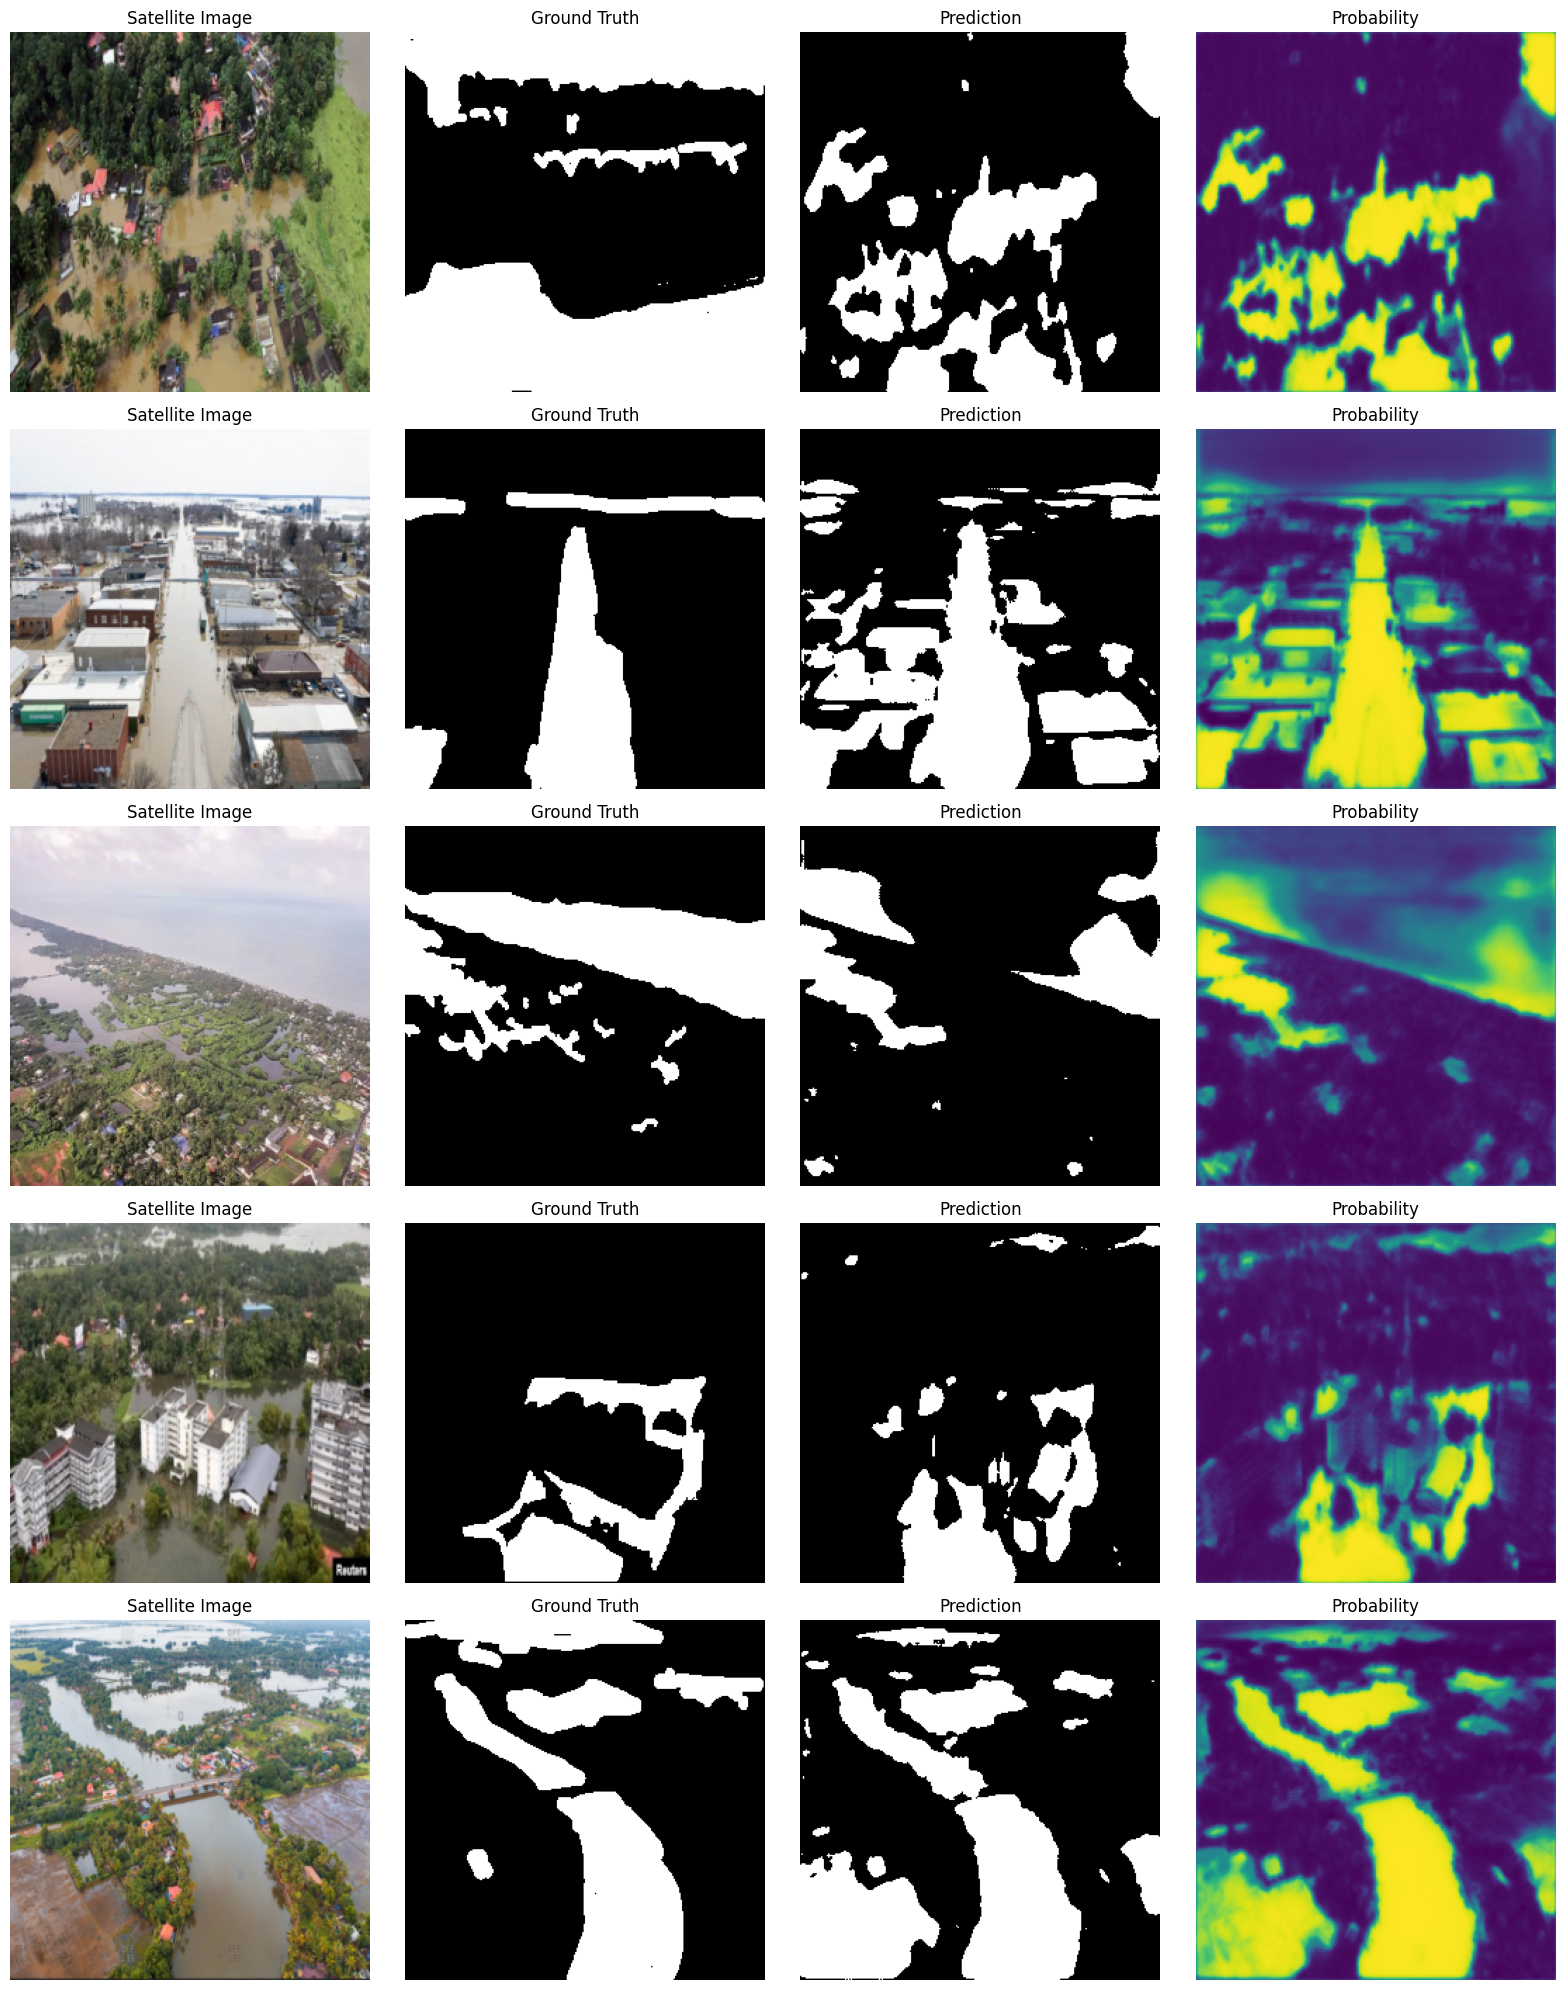

In [10]:
# ============================================================
# VISUALIZE WORST PREDICTIONS
# ============================================================

def show_selected_predictions(
    model,
    dataset,
    indices
):

    model.eval()

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    fig, axes = plt.subplots(
        len(indices),
        4,
        figsize=(16, 4 * len(indices))
    )

    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():

        for row, idx in enumerate(indices):

            image, true_mask = dataset[idx]

            logits = model(
                image.unsqueeze(0).to(device)
            )

            probability = torch.sigmoid(logits)

            prediction = (
                probability >= 0.5
            ).float()

            image_display = (
                image.cpu() * std + mean
            )

            image_display = (
                image_display
                .permute(1, 2, 0)
                .clamp(0, 1)
            )

            axes[row, 0].imshow(
                image_display
            )
            axes[row, 0].set_title(
                "Satellite Image"
            )

            axes[row, 1].imshow(
                true_mask.squeeze(),
                cmap="gray"
            )
            axes[row, 1].set_title(
                "Ground Truth"
            )

            axes[row, 2].imshow(
                prediction.squeeze().cpu(),
                cmap="gray"
            )
            axes[row, 2].set_title(
                "Prediction"
            )

            axes[row, 3].imshow(
                probability.squeeze().cpu(),
                cmap="viridis"
            )
            axes[row, 3].set_title(
                "Probability"
            )

            for col in range(4):
                axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


worst_indices = (
    per_image_results
    .sort_values("iou")
    .head(5)["index"]
    .tolist()
)

show_selected_predictions(
    model,
    val_dataset,
    worst_indices
)

In [11]:
# ============================================================
# THRESHOLD ANALYSIS
# ============================================================

def evaluate_threshold(
    model,
    dataset,
    threshold
):

    model.eval()

    total_iou = 0
    total_dice = 0

    with torch.no_grad():

        for image, mask in dataset:

            logits = model(
                image.unsqueeze(0).to(device)
            )

            probabilities = torch.sigmoid(logits)

            prediction = (
                probabilities >= threshold
            ).float()

            pred = prediction.flatten()
            target = mask.to(device).flatten()

            intersection = (
                pred * target
            ).sum()

            pred_area = pred.sum()
            target_area = target.sum()

            union = (
                pred_area
                + target_area
                - intersection
            )

            iou = (
                intersection + 1e-6
            ) / (
                union + 1e-6
            )

            dice = (
                2 * intersection + 1e-6
            ) / (
                pred_area
                + target_area
                + 1e-6
            )

            total_iou += iou.item()
            total_dice += dice.item()

    n = len(dataset)

    return (
        total_iou / n,
        total_dice / n
    )


threshold_results = []

for threshold in np.arange(
    0.20,
    0.81,
    0.05
):

    iou, dice = evaluate_threshold(
        model,
        val_dataset,
        threshold
    )

    threshold_results.append({
        "threshold": threshold,
        "iou": iou,
        "dice": dice
    })


threshold_df = pd.DataFrame(
    threshold_results
)

print(threshold_df)

    threshold       iou      dice
0        0.20  0.711518  0.823009
1        0.25  0.724318  0.832297
2        0.30  0.732912  0.838331
3        0.35  0.739630  0.842941
4        0.40  0.745236  0.846651
5        0.45  0.749686  0.849431
6        0.50  0.752765  0.851006
7        0.55  0.751516  0.849893
8        0.60  0.748669  0.847707
9        0.65  0.744321  0.844426
10       0.70  0.737677  0.839510
11       0.75  0.728055  0.832467
12       0.80  0.712675  0.821077


In [12]:
print("\nBest threshold by IoU:")

print(
    threshold_df.loc[
        threshold_df["iou"].idxmax()
    ]
)

print("\nBest threshold by Dice:")

print(
    threshold_df.loc[
        threshold_df["dice"].idxmax()
    ]
)


Best threshold by IoU:
threshold    0.500000
iou          0.752765
dice         0.851006
Name: 6, dtype: float64

Best threshold by Dice:
threshold    0.500000
iou          0.752765
dice         0.851006
Name: 6, dtype: float64


In [13]:
# ============================================================
# EXPERIMENT 2
# ImageNet-pretrained ResNet18 Encoder + U-Net Decoder
# ============================================================

import torchvision.models as models


# ============================================================
# 1. PRETRAINED RESNET18
# ============================================================

weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(weights=weights)


# ============================================================
# 2. PRETRAINED U-NET
# ============================================================

class PretrainedUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # ResNet18 encoder
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool

        self.encoder1 = resnet.layer1   # 64
        self.encoder2 = resnet.layer2   # 128
        self.encoder3 = resnet.layer3   # 256
        self.encoder4 = resnet.layer4   # 512

        # Decoder
        self.up1 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )
        self.dec1 = DoubleConv(
            512, 256, dropout=0.10
        )

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec2 = DoubleConv(
            256, 128, dropout=0.10
        )

        self.up3 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec3 = DoubleConv(
            128, 64, dropout=0.10
        )

        self.up4 = nn.ConvTranspose2d(
            64, 64, kernel_size=2, stride=2
        )
        self.dec4 = DoubleConv(
            128, 64, dropout=0.10
        )

        # ResNet's first conv reduces 256 -> 128,
        # so one more upsampling is needed.
        self.up5 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )

        self.final_conv = nn.Conv2d(
            32, 1, kernel_size=1
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        x1 = self.relu(self.bn1(self.conv1(x)))
        x2 = self.encoder1(self.maxpool(x1))
        x3 = self.encoder2(x2)
        x4 = self.encoder3(x3)
        x5 = self.encoder4(x4)

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        x = self.up1(x5)

        if x.shape[2:] != x4.shape[2:]:
            x = F.interpolate(
                x,
                size=x4.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x4, x], dim=1)
        x = self.dec1(x)

        x = self.up2(x)

        if x.shape[2:] != x3.shape[2:]:
            x = F.interpolate(
                x,
                size=x3.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x3, x], dim=1)
        x = self.dec2(x)

        x = self.up3(x)

        if x.shape[2:] != x2.shape[2:]:
            x = F.interpolate(
                x,
                size=x2.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x2, x], dim=1)
        x = self.dec3(x)

        x = self.up4(x)

        if x.shape[2:] != x1.shape[2:]:
            x = F.interpolate(
                x,
                size=x1.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x1, x], dim=1)
        x = self.dec4(x)

        x = self.up5(x)

        # Final output: 256 x 256
        x = self.final_conv(x)

        return x


# ============================================================
# 3. MODEL
# ============================================================

model_pretrained = PretrainedUNet().to(device)


def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print(
    "Trainable parameters:",
    f"{count_parameters(model_pretrained):,}"
)


# ============================================================
# 4. DIFFERENTIAL LEARNING RATES
# ============================================================

encoder_params = [
    model_pretrained.conv1.parameters(),
    model_pretrained.bn1.parameters(),
    model_pretrained.encoder1.parameters(),
    model_pretrained.encoder2.parameters(),
    model_pretrained.encoder3.parameters(),
    model_pretrained.encoder4.parameters()
]

encoder_params = [
    p
    for group in encoder_params
    for p in group
]

decoder_params = [
    model_pretrained.up1.parameters(),
    model_pretrained.dec1.parameters(),
    model_pretrained.up2.parameters(),
    model_pretrained.dec2.parameters(),
    model_pretrained.up3.parameters(),
    model_pretrained.dec3.parameters(),
    model_pretrained.up4.parameters(),
    model_pretrained.dec4.parameters(),
    model_pretrained.up5.parameters(),
    model_pretrained.final_conv.parameters()
]

decoder_params = [
    p
    for group in decoder_params
    for p in group
]


optimizer_pretrained = optim.Adam([
    {
        "params": encoder_params,
        "lr": 1e-5
    },
    {
        "params": decoder_params,
        "lr": 1e-4
    }
])


scheduler_pretrained = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_pretrained,
    mode="min",
    factor=0.1,
    patience=4
)


# ============================================================
# 5. TRAINING FUNCTION
# ============================================================

def train_pretrained_one_epoch():

    model_pretrained.train()

    total_loss = 0

    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer_pretrained.zero_grad()

        logits = model_pretrained(images)

        loss = combined_loss(
            logits,
            masks
        )

        loss.backward()

        optimizer_pretrained.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)


# ============================================================
# 6. VALIDATION FUNCTION
# ============================================================

def validate_pretrained():

    model_pretrained.eval()

    total_loss = 0
    total_iou = 0
    total_dice = 0
    batches = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            logits = model_pretrained(images)

            loss = combined_loss(
                logits,
                masks
            )

            iou, dice = calculate_metrics(
                logits,
                masks
            )

            total_loss += loss.item()
            total_iou += iou
            total_dice += dice

            batches += 1

    return (
        total_loss / batches,
        total_iou / batches,
        total_dice / batches
    )


# ============================================================
# 7. TRAIN
# ============================================================

NUM_EPOCHS = 40
PATIENCE = 8

best_pretrained_loss = float("inf")
best_pretrained_iou = 0
best_pretrained_dice = 0
best_pretrained_epoch = 0

epochs_without_improvement = 0

pretrained_history = []

pretrained_model_path = (
    "/kaggle/working/best_pretrained_unet.pth"
)


for epoch in range(NUM_EPOCHS):

    train_loss = train_pretrained_one_epoch()

    val_loss, val_iou, val_dice = (
        validate_pretrained()
    )

    scheduler_pretrained.step(val_loss)

    encoder_lr = optimizer_pretrained.param_groups[0]["lr"]
    decoder_lr = optimizer_pretrained.param_groups[1]["lr"]

    pretrained_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_iou": val_iou,
        "val_dice": val_dice,
        "encoder_lr": encoder_lr,
        "decoder_lr": decoder_lr
    })

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"IoU: {val_iou:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"Enc LR: {encoder_lr:.1e} | "
        f"Dec LR: {decoder_lr:.1e}"
    )

    if val_loss < best_pretrained_loss:

        best_pretrained_loss = val_loss
        best_pretrained_iou = val_iou
        best_pretrained_dice = val_dice
        best_pretrained_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_pretrained.state_dict(),
                "optimizer_state_dict": optimizer_pretrained.state_dict(),
                "val_loss": val_loss,
                "val_iou": val_iou,
                "val_dice": val_dice
            },
            pretrained_model_path
        )

        print("  -> Best pretrained model saved")

    else:

        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print("Early stopping")

            break


# ============================================================
# 8. LOAD BEST MODEL
# ============================================================

checkpoint_pretrained = torch.load(
    pretrained_model_path,
    map_location=device
)

model_pretrained.load_state_dict(
    checkpoint_pretrained["model_state_dict"]
)

model_pretrained.eval()


# ============================================================
# 9. FINAL VALIDATION
# ============================================================

final_pretrained_loss, final_pretrained_iou, final_pretrained_dice = (
    validate_pretrained()
)


print("\n========================================")
print("EXPERIMENT 2: PRETRAINED U-NET")
print("========================================")

print(
    "Trainable parameters:",
    f"{count_parameters(model_pretrained):,}"
)

print(
    "Best epoch:",
    best_pretrained_epoch
)

print(
    "Best validation loss:",
    f"{best_pretrained_loss:.4f}"
)

print(
    "Best validation IoU:",
    f"{best_pretrained_iou:.4f}"
)

print(
    "Best validation Dice:",
    f"{best_pretrained_dice:.4f}"
)

print("\nFINAL VALIDATION")

print(
    "Validation Loss:",
    f"{final_pretrained_loss:.4f}"
)

print(
    "Validation IoU:",
    f"{final_pretrained_iou:.4f}"
)

print(
    "Validation Dice:",
    f"{final_pretrained_dice:.4f}"
)


# ============================================================
# 10. SAVE HISTORY
# ============================================================

pretrained_history_df = pd.DataFrame(
    pretrained_history
)

pretrained_history_df.to_csv(
    "/kaggle/working/pretrained_unet_history.csv",
    index=False
)


# ============================================================
# 11. PER-IMAGE EVALUATION
# ============================================================

per_image_pretrained = evaluate_per_image(
    model_pretrained,
    val_dataset,
    threshold=0.5
)

print("\n========================================")
print("PER-IMAGE RESULTS")
print("========================================")

print(
    per_image_pretrained[
        ["iou", "dice"]
    ].describe()
)


# ============================================================
# 12. WORST / BEST CASES
# ============================================================

print("\nWorst 10 images:")

print(
    per_image_pretrained
    .sort_values("iou")
    .head(10)
)


print("\nBest 10 images:")

print(
    per_image_pretrained
    .sort_values(
        "iou",
        ascending=False
    )
    .head(10)
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]

Trainable parameters: 14,325,889


Epoch 01/40 | Train Loss: 0.6122 | Val Loss: 0.6180 | IoU: 0.4584 | Dice: 0.6110 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 02/40 | Train Loss: 0.5455 | Val Loss: 0.5304 | IoU: 0.6563 | Dice: 0.7817 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 03/40 | Train Loss: 0.4917 | Val Loss: 0.4476 | IoU: 0.7044 | Dice: 0.8174 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 04/40 | Train Loss: 0.4471 | Val Loss: 0.3834 | IoU: 0.7529 | Dice: 0.8510 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 05/40 | Train Loss: 0.4113 | Val Loss: 0.3698 | IoU: 0.7604 | Dice: 0.8568 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 06/40 | Train Loss: 0.3786 | Val Loss: 0.3465 | IoU: 0.7438 | Dice: 0.8460 | Enc LR: 1.0e-05 | Dec LR: 1.0e-04
  -> Best pretrained model saved
Epoch 07/40 | Train Loss: 0.3492 | Val Loss: 0.3306 | IoU: 0.7522 | Dice: 0.8516 | Enc LR: 1.0e-05 |

In [14]:
# ============================================================
# THRESHOLD ANALYSIS - PRETRAINED U-NET
# ============================================================

pretrained_threshold_results = []

for threshold in np.arange(
    0.20,
    0.81,
    0.05
):

    iou, dice = evaluate_threshold(
        model_pretrained,
        val_dataset,
        threshold
    )

    pretrained_threshold_results.append({
        "threshold": threshold,
        "iou": iou,
        "dice": dice
    })


pretrained_threshold_df = pd.DataFrame(
    pretrained_threshold_results
)

print(pretrained_threshold_df)

print("\nBest threshold by IoU:")

print(
    pretrained_threshold_df.loc[
        pretrained_threshold_df["iou"].idxmax()
    ]
)

print("\nBest threshold by Dice:")

print(
    pretrained_threshold_df.loc[
        pretrained_threshold_df["dice"].idxmax()
    ]
)

    threshold       iou      dice
0        0.20  0.780865  0.870834
1        0.25  0.787039  0.874753
2        0.30  0.791656  0.877646
3        0.35  0.794907  0.879652
4        0.40  0.797425  0.881202
5        0.45  0.798925  0.882093
6        0.50  0.798849  0.881923
7        0.55  0.797183  0.880743
8        0.60  0.794630  0.878970
9        0.65  0.791086  0.876530
10       0.70  0.786035  0.873077
11       0.75  0.779714  0.868735
12       0.80  0.770749  0.862572

Best threshold by IoU:
threshold    0.450000
iou          0.798925
dice         0.882093
Name: 5, dtype: float64

Best threshold by Dice:
threshold    0.450000
iou          0.798925
dice         0.882093
Name: 5, dtype: float64


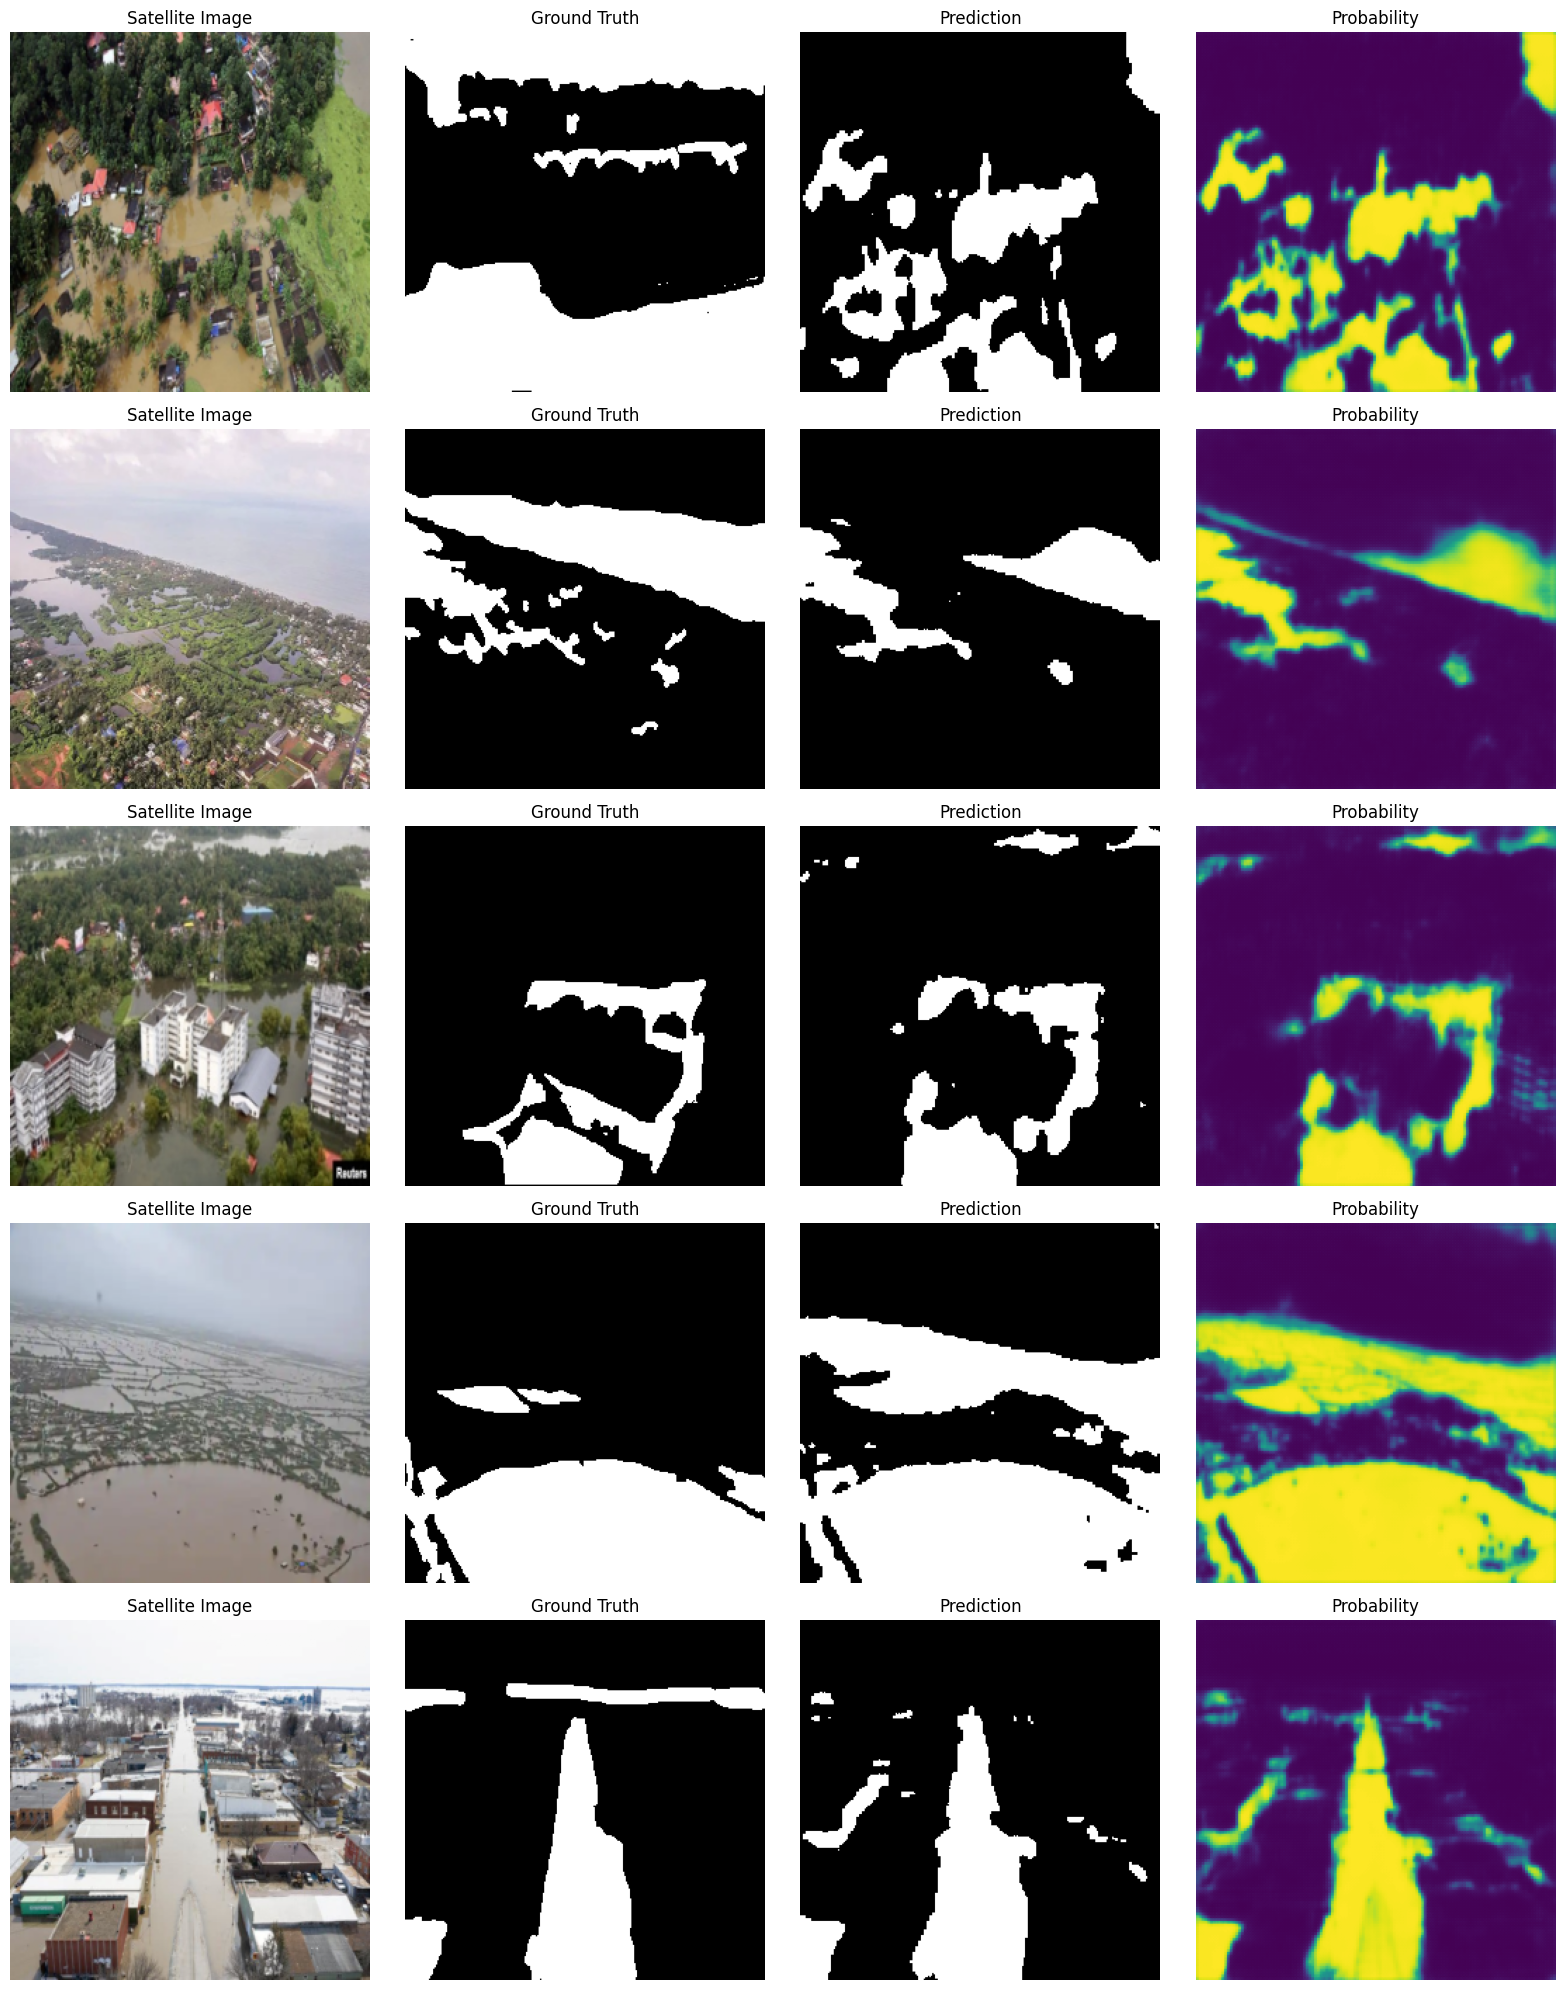

In [15]:
pretrained_worst_indices = (
    per_image_pretrained
    .sort_values("iou")
    .head(5)["index"]
    .tolist()
)

show_selected_predictions(
    model_pretrained,
    val_dataset,
    pretrained_worst_indices
)